In [1]:
!pip install pandas numpy matplotlib wordcloud openpyxl

Defaulting to user installation because normal site-packages is not writeable


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from wordcloud import WordCloud, STOPWORDS

# Load dataset
df = pd.read_csv("flipkart_product.csv",encoding="unicode_escape")

# Display first five records
print(df.head())

# Dataset information
print(df.info())

# Dataset dimensions
print("Dataset Shape:", df.shape)

                                        product_name product_price Rate  \
0  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...      ??3,999    5   
1  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...      ??3,999    5   
2  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...      ??3,999    3   
3  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...      ??3,999    1   
4  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...      ??3,999    3   

            Review                                            Summary  
0           Super!  Great cooler.. excellent air flow and for this...  
1          Awesome             Best budget 2 fit cooler. Nice cooling  
2             Fair  The quality is good but the power of air is de...  
3  Useless product                 Very bad product it's a only a fan  
4             Fair                                      Ok ok product  
<class 'pandas.DataFrame'>
RangeIndex: 189874 entries, 0 to 189873
Data columns (total 5 columns):
 #   Column       

In [16]:
# Standardize column names
df.columns = df.columns.str.strip()

# Clean rating field
df['Rate'] = (
    df['Rate'].astype(str)
    .str.extract(r'(\d+\.?\d*)')[0]
)

df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')

# Clean price field
df['product_price'] = (
    df['product_price'].astype(str)
    .str.replace(r'[^\d.]', '', regex=True)
)

df['product_price'] = pd.to_numeric(
    df['product_price'], errors='coerce'
)

# Remove invalid records
df = df.dropna(
    subset=['product_name', 'Rate', 'product_price']
)

# Keep valid ratings between 1 and 5
df = df[df['Rate'].between(1, 5)]

print("Cleaned Dataset:")
print(df.head())

print("Remaining Records:", len(df))

Cleaned Dataset:
                                        product_name  product_price  Rate  \
0  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...         3999.0   5.0   
1  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...         3999.0   5.0   
2  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...         3999.0   3.0   
3  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...         3999.0   1.0   
4  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...         3999.0   3.0   

            Review                                            Summary  
0           Super!  Great cooler.. excellent air flow and for this...  
1          Awesome             Best budget 2 fit cooler. Nice cooling  
2             Fair  The quality is good but the power of air is de...  
3  Useless product                 Very bad product it's a only a fan  
4             Fair                                      Ok ok product  
Remaining Records: 189871


In [17]:
# Group by product name
items = df.groupby('product_name').agg(
    mean_rating=('Rate', 'mean'),
    mean_price=('product_price', 'mean'),
    total_reviews=('product_name', 'count')
).reset_index()

# Round numerical values
items['mean_rating'] = items['mean_rating'].round(2)
items['mean_price'] = items['mean_price'].round(2)

# Display summary
print("Product-wise Summary:")
print(items.head(10))

Product-wise Summary:
                                        product_name  mean_rating  mean_price  \
0  1170-BL-BR Unique New Day & Date Analog Watch ...         3.99       299.0   
1      38024PP25 Minimalists Analog Watch  - For Men         4.89       850.0   
2  3D METRO SUPER STORE JUICER_Gduumy 1 Juicer,1 ...         3.67       417.0   
3  3D METRO SUPER STORE METRO_MIXER Pro 0 Juicer ...         4.75       199.0   
4             77085PP03 Volt Analog Watch  - For Men         4.71       699.0   
5  7SEVEN Airtel DTH Remote Airtel Xstream Remote...         4.69       219.0   
6  @Home by nilkamal Walton Engineered Wood TV En...         4.44     11999.0   
7   ADONYX Combo of Knee,Palm, Elbow & Ankle Support         3.80       199.0   
8  ADZOY Metal Lazy Stand Bracket for Neck Rest o...         3.52       284.0   
9  AGAMI Green 2 Layer Lucky Bamboo plant with Bi...         4.46       279.0   

   total_reviews  
0            150  
1              9  
2            100  
3         

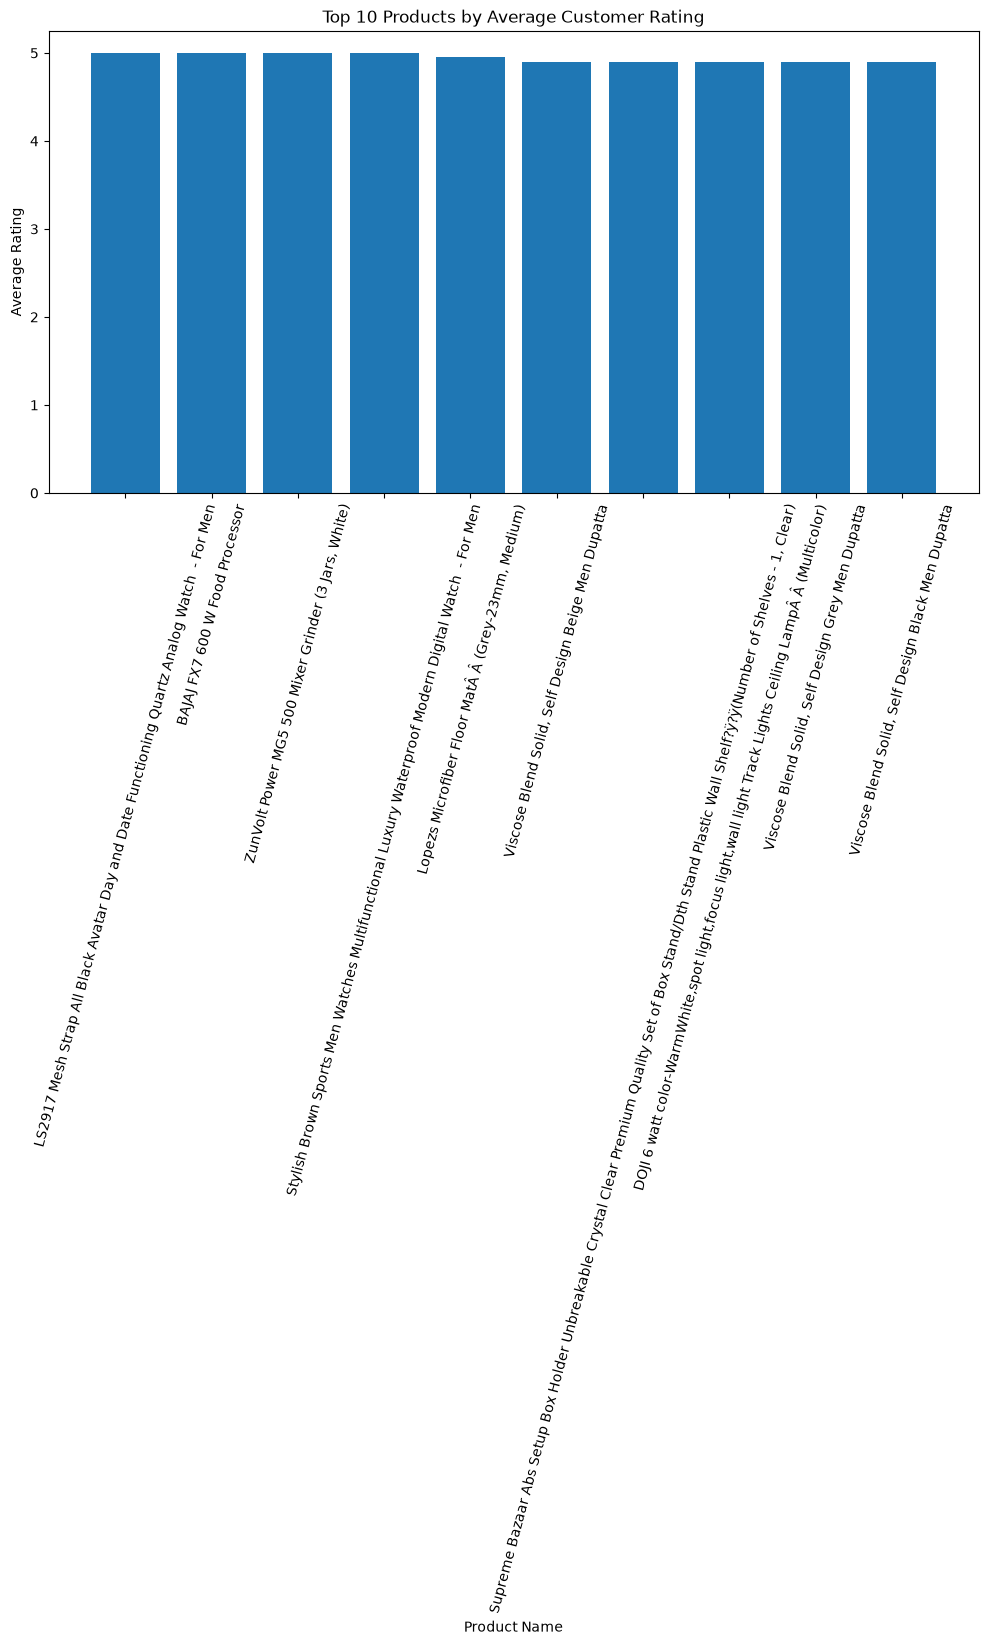

<Figure size 1200x700 with 0 Axes>

In [19]:
top_products = items.sort_values(
    by='mean_rating',
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_products['product_name'],
    top_products['mean_rating']
)

plt.xlabel("Product Name")
plt.ylabel("Average Rating")
plt.title("Top 10 Products by Average Customer Rating")

plt.xticks(rotation=75)
plt.figure(figsize=(12, 7))

# Your plotting code here

plt.tight_layout()
plt.show()
#plt.tight_layout()

#plt.show()

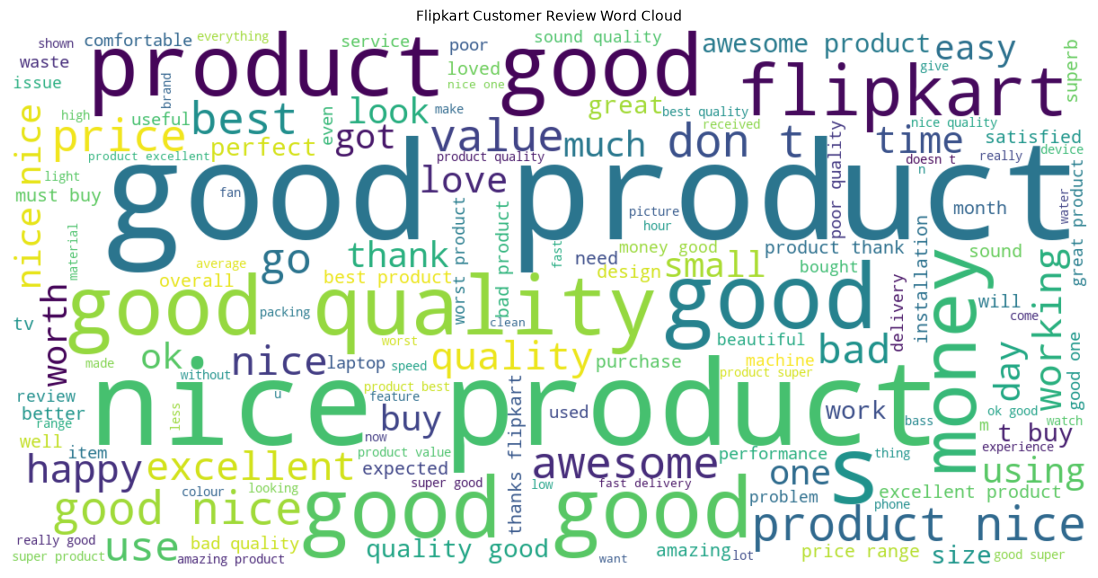

In [21]:
# Combine all customer summaries
text = " ".join(
    df['Summary'].dropna().astype(str)
)

# Convert text to lowercase
text = text.lower()

# Remove special characters and numbers
text = re.sub(r'[^a-z\s]', ' ', text)

# Stopwords
stopwords = set(STOPWORDS)

# Generate Word Cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    stopwords=stopwords,
    max_words=150,
    colormap='viridis'
).generate(text)

# Display Word Cloud
plt.figure(figsize=(15, 7))

plt.imshow(wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title(
    "Flipkart Customer Review Word Cloud",
    fontsize=10
)

plt.show()

In [22]:
# Export summary
items.to_excel(
    "Flipkart_Product_Analytics.xlsx",
    index=False
)

print("Excel report generated successfully!")

Excel report generated successfully!
